## Customer Segmentation Analysis Using K-Means Clustering

## 1. Introduction

Customer segmentation is the process of dividing customers into groups based on similarities in their characteristics and purchasing behaviour. It helps businesses understand their customers and develop targeted marketing strategies.

This project applies the K-Means clustering algorithm to customer data to identify groups with similar purchasing patterns, recency, frequency, and spending behaviour.

## 2. Objectives

1.Analyse customer purchasing and spending behaviour.

2.Clean and prepare the dataset for analysis.

3.Select relevant behavioural features for clustering.

4.Standardise the selected features.

5.Determine a suitable number of clusters using the Elbow Method.

6.Apply K-Means clustering to segment customers.

7.Visualise and profile customer groups.

8.Recommend marketing strategies for different customer segments.

## 3. Dataset Description

The Customer Personality Analysis dataset was obtained from Kaggle. It contains customer demographic information, purchase-channel activity, recency, product-category spending, and marketing campaign responses.

The dataset is used to identify customer groups with similar purchasing and spending patterns.

Dataset source: Customer Personality Analysis — Kaggle

## 4.Important Features

ID: Unique customer identifier.

Income: Customer income.

Recency: Number of days since the customer's last purchase.

NumWebPurchases: Purchases made through the website.

NumCatalogPurchases: Purchases made through the catalogue.

NumStorePurchases: Purchases made in physical stores.

MntWines, MntFruits, MntMeatProducts, MntFishProducts, MntSweetProducts, and MntGoldProds: Spending across product categories.

Purchase frequency and total spending will be derived from the available columns.

## 5. Importing Required Libraries

This section imports the Python libraries required for data manipulation, visualisation, preprocessing, and customer clustering. Pandas and NumPy are used for data analysis, Matplotlib and Seaborn for visualisation, and Scikit-learn for feature standardisation and K-Means clustering.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

sns.set_theme(style="whitegrid")

## 6. Importing Required Libraries

This section imports the Python libraries required for data manipulation, visualisation, preprocessing, and customer clustering. Pandas and NumPy are used for data analysis, Matplotlib and Seaborn for visualisation, and Scikit-learn for feature standardisation and K-Means clustering.

In [16]:
df = pd.read_csv("marketing_campaign.csv", sep="\t")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (2240, 29)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


## 7. Dataset Structure and Data Types

Examining the dataset structure helps identify the number of records, available attributes, and data types. This step helps determine whether the columns are suitable for statistical analysis and clustering.

In [17]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

Dataset shape: (2240, 29)

Column names:
['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome', 'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response']

Data types:
ID                       int64
Year_Birth               int64
Education                  str
Marital_Status             str
Income                 float64
Kidhome                  int64
Teenhome                 int64
Dt_Customer                str
Recency                  int64
MntWines                 int64
MntFruits                int64
MntMeatProducts          int64
MntFishProducts          int64
MntSweetProducts         int64
MntGoldProds             int64
NumDealsPurchases        int64
N

## 8. Checking Missing Values and Duplicates

Missing values and duplicate records can affect the reliability of customer segmentation. This section identifies incomplete records and repeated rows before data cleaning.

In [18]:
print("Missing values:")
display(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Missing values:


ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
AcceptedCmp3            0
AcceptedCmp4            0
AcceptedCmp5            0
AcceptedCmp1            0
AcceptedCmp2            0
Complain                0
Z_CostContact           0
Z_Revenue               0
Response                0
dtype: int64


Duplicate rows: 0


## 9. Data Cleaning and Preprocessing

The dataset is cleaned by removing duplicate records, converting income to a numeric format, and handling records with missing values in important fields. Invalid income and recency values are excluded to prepare reliable data for analysis

In [5]:
df_clean = df.copy()

# Remove duplicate records
df_clean = df_clean.drop_duplicates()

# Convert income to numeric
df_clean["Income"] = pd.to_numeric(
    df_clean["Income"], errors="coerce"
)

# Check missing values
print("Missing values before cleaning:")
print(df_clean.isnull().sum())

# Remove rows missing important customer information
df_clean = df_clean.dropna(
    subset=["ID", "Income", "Recency"]
)

# Keep valid income and recency values
df_clean = df_clean[
    (df_clean["Income"] > 0) &
    (df_clean["Recency"] >= 0)
].copy()

print("\nRows before cleaning:", len(df))
print("Rows after cleaning:", len(df_clean))

print("\nMissing values after cleaning:")
print(df_clean.isnull().sum())

Missing values before cleaning:
ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
AcceptedCmp3            0
AcceptedCmp4            0
AcceptedCmp5            0
AcceptedCmp1            0
AcceptedCmp2            0
Complain                0
Z_CostContact           0
Z_Revenue               0
Response                0
dtype: int64

Rows before cleaning: 2240
Rows after cleaning: 2216

Missing values after cleaning:
ID                     0
Year_Birth             0
Education              0
Marital_Status         0
Income         

## 10. Customer Purchase Frequency and Spending Analysis

Purchase frequency is estimated by combining the recorded web, catalogue, and store purchase counts. Total historical spending is calculated by adding spending across the six product categories. Average purchase value is estimated by dividing total spending by the combined purchase count.

In [7]:
# Purchase frequency across channels
purchase_columns = [
    "NumWebPurchases",
    "NumCatalogPurchases",
    "NumStorePurchases"
]

df_clean["Frequency"] = df_clean[purchase_columns].sum(axis=1)

# Total spending across product categories
spending_columns = [
    "MntWines",
    "MntFruits",
    "MntMeatProducts",
    "MntFishProducts",
    "MntSweetProducts",
    "MntGoldProds"
]

df_clean["Monetary"] = df_clean[spending_columns].sum(axis=1)

# Average spending per recorded purchase
df_clean["AveragePurchaseValue"] = (
    df_clean["Monetary"] /
    df_clean["Frequency"].replace(0, np.nan)
)

# Historical customer value proxy, not predicted lifetime value
df_clean["CustomerValueProxy"] = df_clean["Monetary"]

display(
    df_clean[
        ["ID", "Recency", "Frequency", "Monetary",
         "AveragePurchaseValue", "CustomerValueProxy"]
    ].head()
)

display(
    df_clean[
        ["Recency", "Frequency", "Monetary",
         "AveragePurchaseValue"]
    ].describe().T
)

,ID,Recency,Frequency,Monetary,AveragePurchaseValue,CustomerValueProxy
0,5524,58,22,1617,73.500000,1617
1,2174,38,4,27,6.750000,27
2,4141,26,20,776,38.800000,776
3,6182,26,6,53,8.833333,53
4,5324,94,14,422,30.142857,422


,count,mean,std,min,25%,50%,75%,max
Recency,2216.0,49.012635,28.948352,0.000000,24.0,49.00000,74.000000,99.000000
Frequency,2216.0,12.557310,7.204611,0.000000,6.0,12.00000,18.000000,32.000000
Monetary,2216.0,607.075361,602.900476,5.000000,69.0,396.50000,1048.000000,2525.000000
AveragePurchaseValue,2210.0,37.556205,30.123926,2.666667,13.0,29.89011,49.416667,187.666667


## 11. Exploratory Data Analysis — Customer Income Distribution

A histogram is used to examine the distribution of customer income. It helps identify common income ranges, the spread of values, and potential skewness in the dataset.

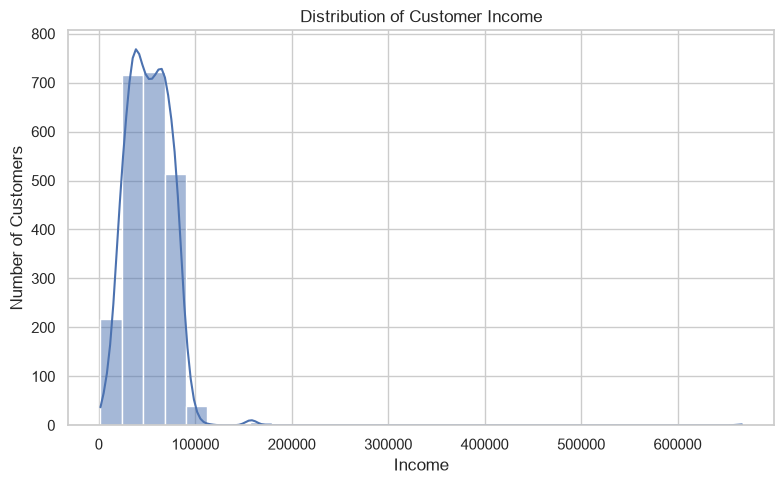

In [19]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_clean,
    x="Income",
    bins=30,
    kde=True
)

plt.title("Distribution of Customer Income")
plt.xlabel("Income")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

## Observation 

Describe the income range containing the largest concentration of customers and whether the distribution appears symmetric or skewed. Mention any unusually high income values if visible.

## 12. Feature Selection for Customer Segmentation

Feature selection identifies the behavioural variables used to group customers. Recency, Frequency, and Monetary are selected because they represent how recently customers purchased, how frequently they purchase across channels, and how much they have spent historically.

In [8]:
features = df_clean[
    ["Recency", "Frequency", "Monetary"]
].copy()

display(features.head())

print("Selected features:", features.columns.tolist())

,Recency,Frequency,Monetary
0,58,22,1617
1,38,4,27
2,26,20,776
3,26,6,53
4,94,14,422


Selected features: ['Recency', 'Frequency', 'Monetary']


## Observation:

Three behavioural features were selected for clustering. They represent different aspects of customer purchasing behaviour and provide a basis for identifying distinct customer groups.

## 13. Feature Transformation and Standardisation

Purchase frequency and monetary spending can have highly skewed distributions. A logarithmic transformation is applied to these two variables to reduce skewness, followed by standardisation using StandardScaler. This ensures that features with larger numerical ranges do not dominate the clustering process.

In [20]:
features_log = features.copy()

features_log[["Frequency", "Monetary"]] = np.log1p(
    features_log[["Frequency", "Monetary"]]
)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(features_log)

print("Standardised data shape:", X_scaled.shape)
print("Number of customers:", X_scaled.shape[0])
print("Number of features:", X_scaled.shape[1])

Standardised data shape: (2216, 3)
Number of customers: 2216
Number of features: 3


## 14. Determining the Optimal Number of Clusters — Elbow Method

The Elbow Method helps identify a suitable number of customer clusters. K-Means is fitted using different values of K, and the inertia for each model is recorded. The resulting curve helps identify where adding more clusters produces diminishing improvements.

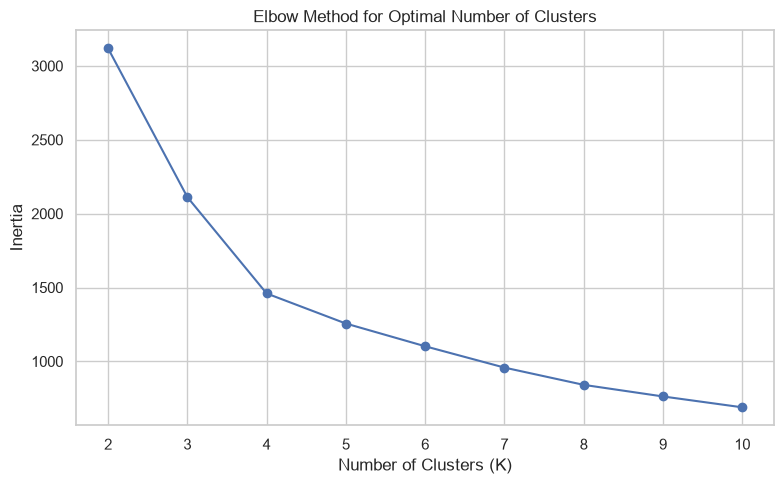

In [10]:
inertia_values = []
k_values = range(2, 11)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X_scaled)
    inertia_values.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertia_values, marker="o")
plt.title("Elbow Method for Optimal Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.tight_layout()
plt.show()

## Observation 

Identify the approximate elbow point where the inertia reduction begins to slow. State the value of K you selected and briefly explain why it is appropriate for this dataset.

## 15. Applying the K-Means Clustering Algorithm

K-Means is applied to divide customers into groups based on similarities in their standardised behavioural features. The number of clusters is selected using the Elbow Method. Each customer receives a cluster label representing their assigned group.

In [21]:
optimal_k = 4  # Change this based on your Elbow chart

kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

df_clean["Cluster"] = kmeans.fit_predict(X_scaled)

print("K-Means clustering completed.")
print("Number of clusters:", optimal_k)

display(df_clean[["ID", "Recency", "Frequency", "Monetary", "Cluster"]].head())

K-Means clustering completed.
Number of clusters: 4


,ID,Recency,Frequency,Monetary,Cluster
0,5524,58,22,1617,1
1,2174,38,4,27,0
2,4141,26,20,776,3
3,6182,26,6,53,0
4,5324,94,14,422,1


## 16. Customer Cluster Visualisation — Frequency vs Monetary

This scatter plot visualises customer clusters using purchase frequency and total historical spending. The different colours represent the clusters assigned by K-Means, allowing comparison of customer purchasing patterns.

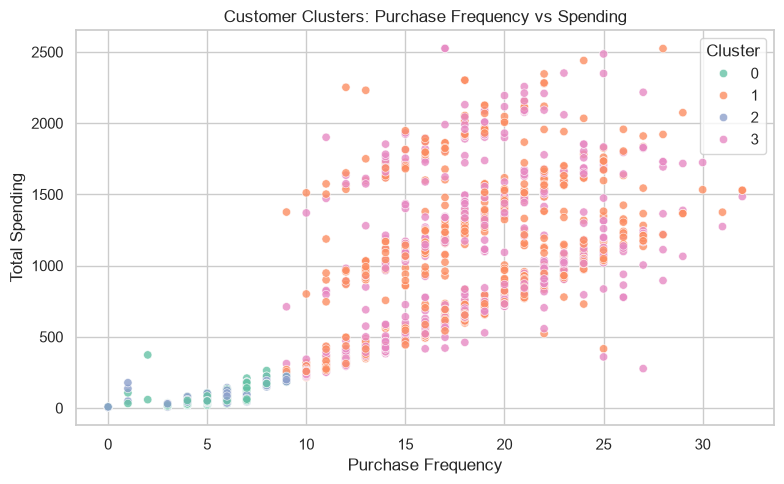

In [12]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_clean,
    x="Frequency",
    y="Monetary",
    hue="Cluster",
    palette="Set2",
    alpha=0.8
)

plt.title("Customer Clusters: Purchase Frequency vs Spending")
plt.xlabel("Purchase Frequency")
plt.ylabel("Total Spending")
plt.tight_layout()
plt.show()

## Observation

Describe how the clusters differ in purchase frequency and spending. Identify any group with relatively high spending or frequent purchases, based on the plotted points.

## 17. Customer Cluster Visualisation — Recency vs Monetary

This scatter plot compares customer recency with total historical spending. It helps examine whether customers who purchased more recently tend to differ in spending from those who have not purchased for a longer period.

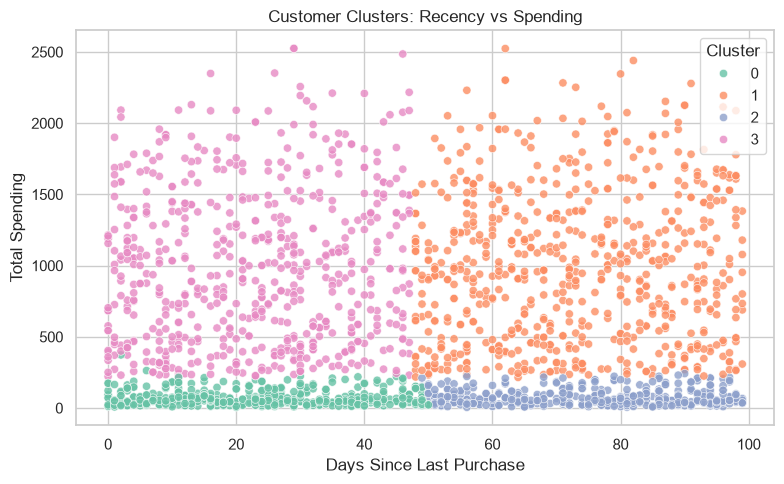

In [13]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_clean,
    x="Recency",
    y="Monetary",
    hue="Cluster",
    palette="Set2",
    alpha=0.8
)

plt.title("Customer Clusters: Recency vs Spending")
plt.xlabel("Days Since Last Purchase")
plt.ylabel("Total Spending")
plt.tight_layout()
plt.show()

## Observation 

Describe the distribution of clusters across recency and spending. Note whether any cluster contains customers with relatively high recency and low spending, which could indicate a potential re-engagement opportunity.

## 18. Customer Cluster Profiling

Cluster profiling summarises the characteristics of each customer group. The mean recency, purchase frequency, total spending, and average purchase value are calculated to help interpret the groups and develop suitable marketing strategies.

In [14]:
cluster_profile = df_clean.groupby("Cluster").agg(
    CustomerCount=("ID", "count"),
    AvgRecency=("Recency", "mean"),
    AvgFrequency=("Frequency", "mean"),
    AvgMonetary=("Monetary", "mean"),
    AvgPurchaseValue=("AveragePurchaseValue", "mean")
).round(2)

display(cluster_profile)

,CustomerCount,AvgRecency,AvgFrequency,AvgMonetary,AvgPurchaseValue
Cluster,,,,,
0,474,24.78,5.18,70.87,12.87
1,684,72.55,17.67,989.39,55.09
2,446,75.02,5.35,76.15,13.55
3,612,22.52,17.82,981.99,54.34


## 19. Distribution of Customers Across Clusters

A bar chart is used to compare the number of customers assigned to each cluster. It reveals the relative size of the segments and helps identify groups that represent a larger or smaller proportion of the customer base.

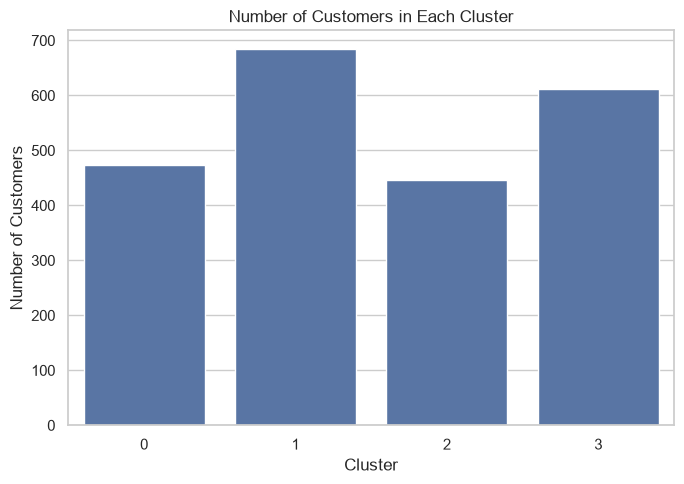

,Customer Count
Cluster,
0,474
1,684
2,446
3,612


In [15]:
cluster_counts = (
    df_clean["Cluster"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(7, 5))

sns.barplot(
    x=cluster_counts.index.astype(str),
    y=cluster_counts.values
)

plt.title("Number of Customers in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

display(cluster_counts.rename("Customer Count").to_frame())

## Observation

State which cluster contains the most customers and which contains the fewest. Explain how segment size can help businesses allocate marketing resources.

## 20. Marketing Recommendations And Conclusion

Marketing Recommendations

The cluster profiles are used to recommend targeted marketing actions. Recommendations should reflect the actual characteristics of each group rather than relying solely on the cluster numbers.
- High spending and frequent purchases: introduce loyalty rewards, exclusive offers, and early access to new products.
- Recent customers with lower purchase frequency: provide personalised recommendations and incentives to encourage repeat purchases.
- High recency and low spending: consider re-engagement campaigns and carefully targeted discounts.
- Other customer groups: tailor product bundles and promotional messages to their observed spending and purchase patterns.
Observation: Customer segmentation provides a basis for differentiated marketing strategies. The recommendations can help improve customer engagement and make promotional campaigns more relevant.

 Conclusion

Customer segmentation was performed using the Customer Personality Analysis dataset. The data was cleaned, behavioural features were derived, and the selected features were transformed and standardised. The Elbow Method was used to choose a suitable number of clusters, and K-Means was applied to group customers based on their recency, purchase frequency, and historical spending.

The resulting visualisations and cluster profiles help identify differences in customer behaviour and support targeted marketing recommendations. However, the dataset contains aggregated customer purchase information rather than individual transaction histories, so purchase frequency and average purchase value are estimates, and historical spending is used as a customer-value proxy rather than predicted customer lifetime value.